# 03 - Outlier Detection and Treatment
**Goal:** flag outliers with three methods and treat them.

In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import cleaning as cl
RAW = "../data/raw/airline_passengers_dirty.csv"
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
s = cl.fill_missing(cl.load_series(RAW), 'time')

## Detect with Z-score, IQR and rolling median
Z-score and IQR assume no trend, so they may miss outliers inside a trending/seasonal series. The rolling median adapts locally.

In [3]:
masks = {'Z-score': cl.outliers_zscore(s), 'IQR': cl.outliers_iqr(s), 'Rolling median': cl.outliers_rolling_median(s)}
for name, m in masks.items():
    print(f'{name:15s} flagged {m.sum()}', s[m].index.strftime('%Y-%m').tolist())

Z-score         flagged 1 ['1955-02']
IQR             flagged 1 ['1955-02']
Rolling median  flagged 3 ['1950-07', '1955-02', '1958-04']


## Plot flagged points

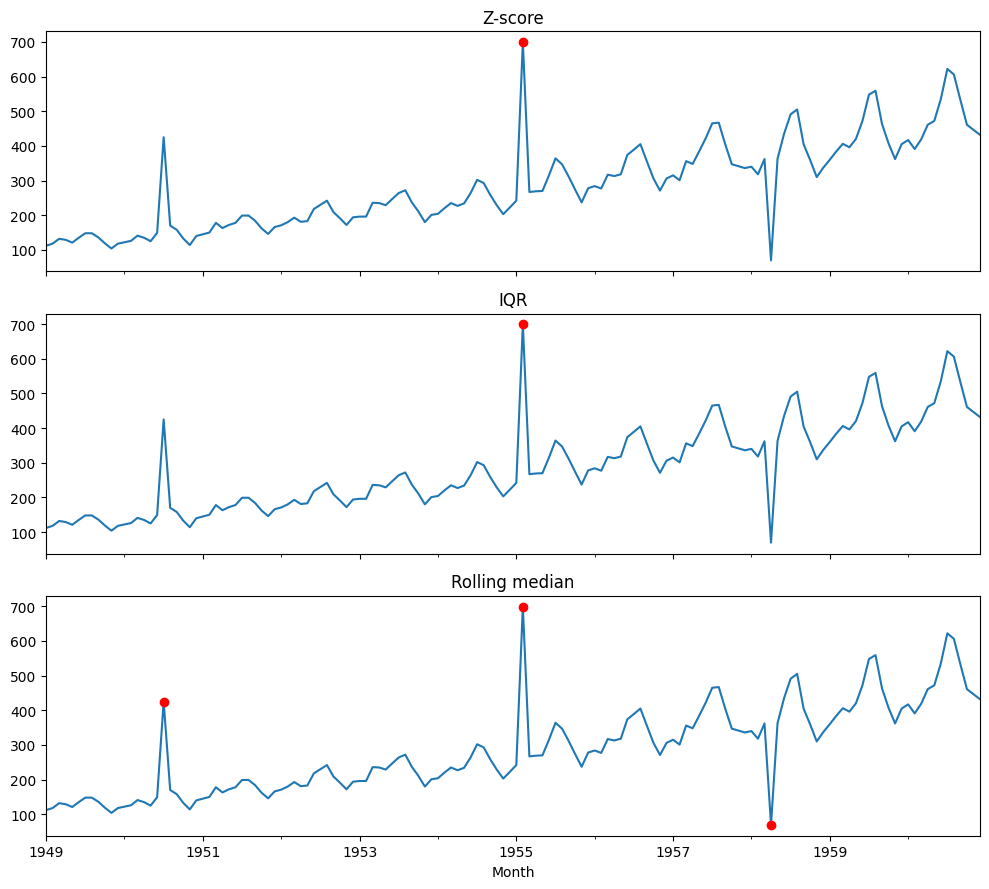

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, (name, m) in zip(axes, masks.items()):
    s.plot(ax=ax); s[m].plot(ax=ax, ls='', marker='o', color='red')
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Treat outliers
We replace flagged points with NaN and interpolate, using the rolling-median mask.

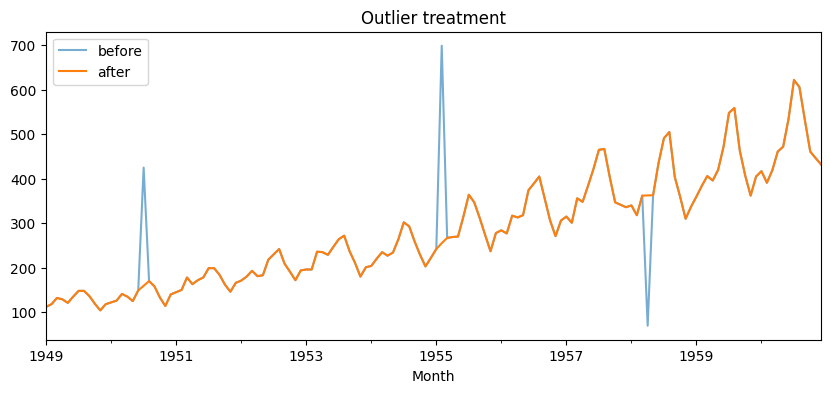

In [5]:
s_clean = cl.treat_outliers(s, masks['Rolling median'])
s.plot(label='before', alpha=.6); s_clean.plot(label='after')
plt.legend(); plt.title('Outlier treatment'); plt.show()